# Diffusion (DDPM) + Flow Matching 生成模型对比实验

用 **MNIST** 完成一个生成模型实验，对比两条主流的“噪声→数据”生成路线：

| 方法 | 学的是什么 | 生成方式 |
| --- | --- | --- |
| **Diffusion（DDPM）** | 预测加噪样本里的噪声 $\epsilon$ | 反向去噪（用 DDIM 当 ODE 采样） |
| **Flow Matching** | 预测直线插值路径上的速度场 $v = x_1 - x_0$ | 对 ODE 做 Euler 积分 |

两者共用一个 **时间条件 U-Net**（结构完全相同、分别训练），保证对比公平。

**核心直觉**：扩散模型是从“纯噪声”开始一步步“去噪”；Flow Matching 是从“纯噪声”出发，沿着学到的速度场直接把噪声“推”成数据。

In [1]:
import math, os, time
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import matplotlib.pyplot as plt
from pathlib import Path

# 让 matplotlib 正确显示中文（macOS 自带字体）
plt.rcParams['font.sans-serif'] = ['Arial Unicode MS', 'Hiragino Sans GB', 'Songti SC']
plt.rcParams['axes.unicode_minus'] = False
from torch.utils.data import DataLoader
from torchvision import datasets, transforms

%matplotlib inline

seed = 42
torch.manual_seed(seed)
np.random.seed(seed)

device = torch.device('mps' if torch.backends.mps.is_available() else 'cpu')
print('Using device:', device)

Using device: mps


In [2]:
# ---------- 数据：桌面 data 文件夹里的 MNIST ----------
data_root = Path('/Users/chris/Desktop/data')

transform = transforms.ToTensor()   # 把像素归一化到 [0, 1]
train_set = datasets.MNIST(root=str(data_root), train=True,  download=False, transform=transform)
test_set  = datasets.MNIST(root=str(data_root), train=False, download=False, transform=transform)

batch_size = 256
train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=True, drop_last=True)

print('train:', len(train_set), ' test:', len(test_set), ' batches/epoch:', len(train_loader))

train: 60000  test: 10000  batches/epoch: 234


In [3]:
# ---------- 时间条件 U-Net（Diffusion 和 Flow Matching 共用同一结构） ----------
class TimeEmbedding(nn.Module):
    def __init__(self, dim):
        super().__init__()
        self.net = nn.Sequential(nn.Linear(1, dim), nn.SiLU(), nn.Linear(dim, dim))
    def forward(self, t):          # t: (B, 1)，取值已归一化到 [0, 1]
        return self.net(t)

class ResBlock(nn.Module):
    def __init__(self, ch, temb_dim):
        super().__init__()
        self.norm1 = nn.GroupNorm(8, ch)
        self.conv1 = nn.Conv2d(ch, ch, 3, padding=1)
        self.norm2 = nn.GroupNorm(8, ch)
        self.conv2 = nn.Conv2d(ch, ch, 3, padding=1)
        self.t_proj = nn.Linear(temb_dim, ch)
    def forward(self, x, temb):
        h = F.silu(self.norm1(x))
        h = self.conv1(h)
        h = h + self.t_proj(temb)[:, :, None, None]
        h = F.silu(self.norm2(h))
        h = self.conv2(h)
        return x + h

class UNet(nn.Module):
    def __init__(self, in_ch=1, base=32, ch_mult=(1, 2), temb_dim=64):
        super().__init__()
        self.time_emb = TimeEmbedding(temb_dim)
        self.in_conv = nn.Conv2d(in_ch, base, 3, padding=1)
        self.downs, self.ups = nn.ModuleList(), nn.ModuleList()
        ch = base
        for m in ch_mult:
            self.downs.append(nn.ModuleList([ResBlock(ch, temb_dim),
                                             nn.Conv2d(ch, ch * m, 3, stride=2, padding=1)]))
            ch *= m
        self.mid = ResBlock(ch, temb_dim)
        for m in reversed(ch_mult):
            self.ups.append(nn.ModuleList([nn.ConvTranspose2d(ch, ch // m, 4, stride=2, padding=1),
                                           ResBlock(ch // m, temb_dim)]))
            ch //= m
        self.out = nn.Sequential(nn.GroupNorm(8, ch), nn.SiLU(), nn.Conv2d(ch, in_ch, 3, padding=1))

    def forward(self, x, t):
        temb = self.time_emb(t)
        h = self.in_conv(x)
        skips = []
        for block, down in self.downs:
            h = block(h, temb)
            skips.append(h)
            h = down(h)
        h = self.mid(h, temb)
        for up, block in self.ups:
            h = up(h)
            h = h + skips.pop()
            h = block(h, temb)
        return self.out(h)

dummy = UNet()
print('UNet params:', sum(p.numel() for p in dummy.parameters()))

UNet params: 243009


## 1. Diffusion（DDPM）

**前向加噪**（训练时构造监督信号）：

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\,\epsilon,\quad \epsilon\sim\mathcal N(0,I)$$

网络学预测噪声 $\epsilon$，损失就是 $\|\epsilon_\theta(x_t,t)-\epsilon\|^2$。

**生成**：从 $x_T\sim\mathcal N(0,I)$ 出发，用 DDIM 的确定性公式一步步“去噪”回到 $x_0$。

In [4]:
# ---------- 加噪调度 ----------
T = 1000
betas = torch.linspace(1e-4, 0.02, T, device=device)   # 线性噪声表（放到 device 上，便于 GPU/MPS 索引）
alphas = 1.0 - betas
alpha_bar = torch.cumprod(alphas, dim=0)      # \\bar\\alpha_t
print('schedule ready, T =', T)

schedule ready, T = 1000


In [5]:
# ---------- 训练 Diffusion：预测噪声 ----------
diff_model = UNet().to(device)
diff_opt = torch.optim.AdamW(diff_model.parameters(), lr=1e-3, weight_decay=1e-4)
diff_epochs = 20
diff_losses = []

for epoch in range(diff_epochs):
    diff_model.train()
    total = 0.0
    for x, _ in train_loader:
        x = x.to(device)
        b = x.shape[0]

        t_idx = torch.randint(0, T, (b,), device=device)   # 随机时间步
        t = (t_idx.float() / T).view(b, 1)                  # 归一化到 [0,1)
        noise = torch.randn_like(x)

        ab = alpha_bar[t_idx].view(b, 1, 1, 1)
        x_t = torch.sqrt(ab) * x + torch.sqrt(1 - ab) * noise   # 前向加噪

        pred = diff_model(x_t, t)                               # 预测噪声
        loss = F.mse_loss(pred, noise)

        diff_opt.zero_grad(); loss.backward(); diff_opt.step()
        total += loss.item() * b

    avg = total / len(train_set)
    diff_losses.append(avg)
    print(f'Diffusion epoch {epoch+1:2d}/{diff_epochs}  loss={avg:.4f}')

print('Diffusion 训练完成')

Diffusion epoch  1/20  loss=0.0586
Diffusion epoch  2/20  loss=0.0257
Diffusion epoch  3/20  loss=0.0224
Diffusion epoch  4/20  loss=0.0208
Diffusion epoch  5/20  loss=0.0195
Diffusion epoch  6/20  loss=0.0187
Diffusion epoch  7/20  loss=0.0181
Diffusion epoch  8/20  loss=0.0178
Diffusion epoch  9/20  loss=0.0175
Diffusion epoch 10/20  loss=0.0170
Diffusion epoch 11/20  loss=0.0171
Diffusion epoch 12/20  loss=0.0170
Diffusion epoch 13/20  loss=0.0167
Diffusion epoch 14/20  loss=0.0166
Diffusion epoch 15/20  loss=0.0165
Diffusion epoch 16/20  loss=0.0163
Diffusion epoch 17/20  loss=0.0162
Diffusion epoch 18/20  loss=0.0163
Diffusion epoch 19/20  loss=0.0161
Diffusion epoch 20/20  loss=0.0161
Diffusion 训练完成


In [6]:
# ---------- DDIM 采样（确定性 ODE，快速） ----------
@torch.no_grad()
def ddim_step(model, x, t, t_next):
    n = x.shape[0]
    tvec = torch.full((n, 1), float(t) / T, device=device)
    eps = model(x, tvec)
    ab      = alpha_bar[t].view(1, 1, 1, 1)
    ab_next = alpha_bar[t_next].view(1, 1, 1, 1)
    x0 = (x - torch.sqrt(1 - ab) * eps) / torch.sqrt(ab).clamp(min=1e-8)
    return torch.sqrt(ab_next) * x0 + torch.sqrt(1 - ab_next) * eps

@torch.no_grad()
def ddim_sample(model, n_samples=64, steps=100):
    model.eval()
    x = torch.randn(n_samples, 1, 28, 28, device=device)
    ts = torch.linspace(T - 1, 0, steps + 1, device=device).long()
    for i in range(steps):
        x = ddim_step(model, x, ts[i], ts[i + 1])
    return x.clamp(0, 1)

@torch.no_grad()
def ddim_trajectory(model, n=8, steps=100):
    model.eval()
    x = torch.randn(n, 1, 28, 28, device=device)
    frames = [x.clone()]
    ts = torch.linspace(T - 1, 0, steps + 1, device=device).long()
    for i in range(steps):
        x = ddim_step(model, x, ts[i], ts[i + 1])
        frames.append(x.clone())
    return frames

print('DDIM sampler ready')

DDIM sampler ready


## 2. Flow Matching

把“噪声 $x_1$ 到数据 $x_0$”看成一条直线路径：

$$x_t = (1-t)\,x_0 + t\,x_1,\quad t\in[0,1]$$

这条路径的速度是常数 $v = x_1 - x_0$。网络学预测这个速度场，损失是 $\|v_\theta(x_t,t)-(x_1-x_0)\|^2$。

**生成**：从 $x_1\sim\mathcal N(0,I)$ 出发，对 ODE $\dot x = v_\theta(x,t)$ 做 Euler 积分，把 $t$ 从 1 积到 0。

In [7]:
# ---------- 训练 Flow Matching：预测速度场 ----------
flow_model = UNet().to(device)
flow_opt = torch.optim.AdamW(flow_model.parameters(), lr=1e-3, weight_decay=1e-4)
flow_epochs = 20
flow_losses = []

for epoch in range(flow_epochs):
    flow_model.train()
    total = 0.0
    for x0, _ in train_loader:
        x0 = x0.to(device)
        b = x0.shape[0]

        t  = torch.rand(b, 1, 1, 1, device=device)  # t ~ U[0,1]
        x1 = torch.randn_like(x0)                  # 目标噪声
        x_t = (1 - t) * x0 + t * x1                # 直线插值路径
        v_target = x1 - x0                         # 真实速度

        v_pred = flow_model(x_t, t.view(b, 1))
        loss = F.mse_loss(v_pred, v_target)

        flow_opt.zero_grad(); loss.backward(); flow_opt.step()
        total += loss.item() * b

    avg = total / len(train_set)
    flow_losses.append(avg)
    print(f'FlowMatching epoch {epoch+1:2d}/{flow_epochs}  loss={avg:.4f}')

print('Flow Matching 训练完成')

FlowMatching epoch  1/20  loss=0.1744
FlowMatching epoch  2/20  loss=0.1151
FlowMatching epoch  3/20  loss=0.1069
FlowMatching epoch  4/20  loss=0.1025
FlowMatching epoch  5/20  loss=0.1000
FlowMatching epoch  6/20  loss=0.0989
FlowMatching epoch  7/20  loss=0.0972
FlowMatching epoch  8/20  loss=0.0965
FlowMatching epoch  9/20  loss=0.0948
FlowMatching epoch 10/20  loss=0.0945
FlowMatching epoch 11/20  loss=0.0940
FlowMatching epoch 12/20  loss=0.0934
FlowMatching epoch 13/20  loss=0.0931
FlowMatching epoch 14/20  loss=0.0925
FlowMatching epoch 15/20  loss=0.0921
FlowMatching epoch 16/20  loss=0.0919
FlowMatching epoch 17/20  loss=0.0918
FlowMatching epoch 18/20  loss=0.0913
FlowMatching epoch 19/20  loss=0.0911
FlowMatching epoch 20/20  loss=0.0905
Flow Matching 训练完成


In [8]:
# ---------- Flow Matching 采样：Euler 解 ODE ----------
@torch.no_grad()
def flow_sample(model, n_samples=64, steps=100):
    model.eval()
    x = torch.randn(n_samples, 1, 28, 28, device=device)
    ts = torch.linspace(1.0, 0.0, steps + 1)
    for i in range(steps):
        t  = ts[i]
        dt = ts[i + 1] - ts[i]
        tvec = torch.full((n_samples, 1), t, device=device)
        x = x + model(x, tvec) * dt
    return x.clamp(0, 1)

@torch.no_grad()
def flow_trajectory(model, n=8, steps=100):
    model.eval()
    x = torch.randn(n, 1, 28, 28, device=device)
    frames = [x.clone()]
    ts = torch.linspace(1.0, 0.0, steps + 1)
    for i in range(steps):
        t  = ts[i]
        dt = ts[i + 1] - ts[i]
        tvec = torch.full((n, 1), t, device=device)
        x = x + model(x, tvec) * dt
        frames.append(x.clone())
    return frames

print('Flow sampler ready')

Flow sampler ready


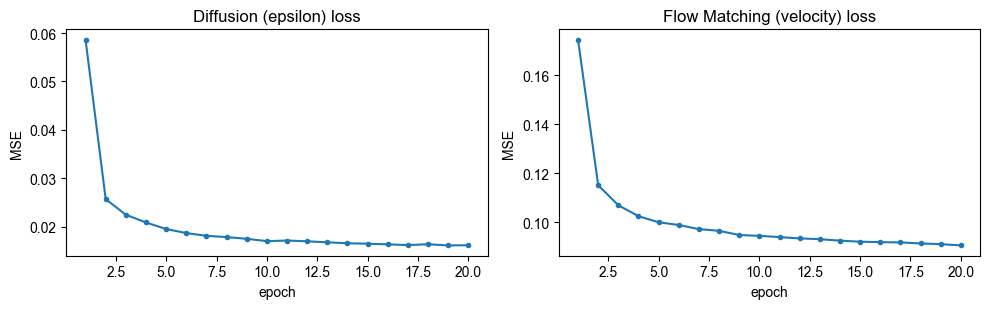

In [9]:
# ---------- 训练损失曲线 ----------
fig, axes = plt.subplots(1, 2, figsize=(10, 3.2))
axes[0].plot(range(1, len(diff_losses)+1), diff_losses, marker='o', ms=3)
axes[0].set_title('Diffusion (epsilon) loss')
axes[0].set_xlabel('epoch'); axes[0].set_ylabel('MSE')
axes[1].plot(range(1, len(flow_losses)+1), flow_losses, marker='o', ms=3)
axes[1].set_title('Flow Matching (velocity) loss')
axes[1].set_xlabel('epoch'); axes[1].set_ylabel('MSE')
plt.tight_layout(); plt.show()

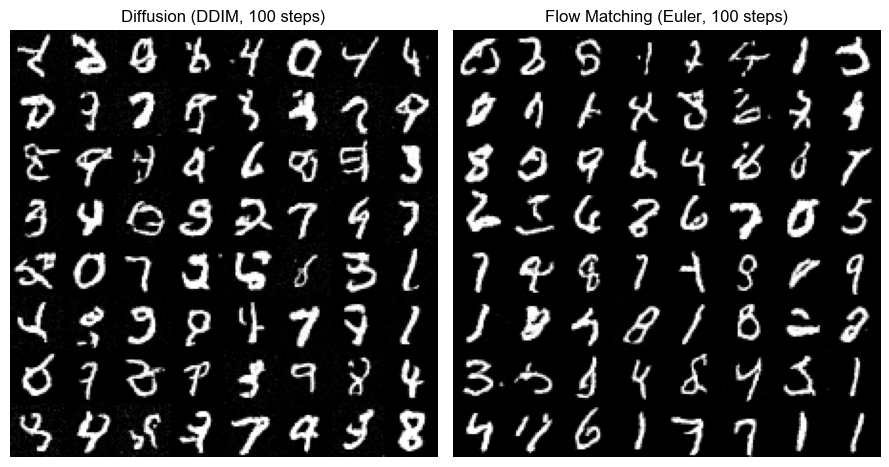

In [10]:
# ---------- 采样对比：各生成 64 张 ----------
n = 64
diff_imgs = ddim_sample(diff_model, n, steps=100).cpu()
flow_imgs = flow_sample(flow_model, n, steps=100).cpu()

def show_grid(imgs, title, ax):
    k = int(math.sqrt(len(imgs)))
    grid = imgs.view(k, k, 28, 28).permute(0, 2, 1, 3).reshape(k*28, k*28)
    ax.imshow(grid, cmap='gray', vmin=0, vmax=1)
    ax.set_title(title); ax.axis('off')

fig, axes = plt.subplots(1, 2, figsize=(9, 4.6))
show_grid(diff_imgs, 'Diffusion (DDIM, 100 steps)', axes[0])
show_grid(flow_imgs, 'Flow Matching (Euler, 100 steps)', axes[1])
plt.tight_layout(); plt.show()

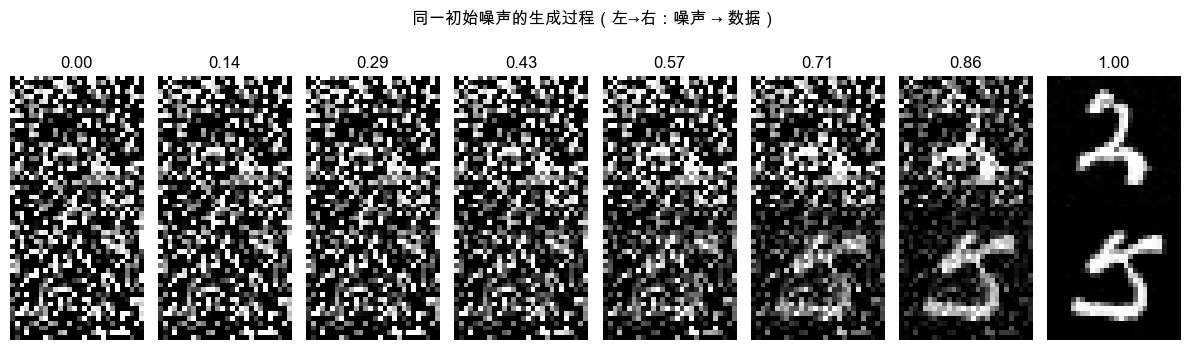

In [16]:
# ---------- 生成轨迹：从纯噪声到数字 ----------
diff_frames = ddim_trajectory(diff_model, n=8, steps=100)
flow_frames = flow_trajectory(flow_model, n=8, steps=100)

def pick_frames(frames, k=8):
    idx = np.linspace(0, len(frames)-1, k).astype(int)
    return [frames[i] for i in idx]

d_frames = pick_frames(diff_frames)
f_frames = pick_frames(flow_frames)

fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for j, fr in enumerate(d_frames):
    axes[0, j].imshow(fr[0, 0].cpu(), cmap='gray', vmin=0, vmax=1); axes[0, j].axis('off')
for j, fr in enumerate(f_frames):
    axes[1, j].imshow(fr[0, 0].cpu(), cmap='gray', vmin=0, vmax=1); axes[1, j].axis('off')
axes[0, 0].set_ylabel('Diffusion'); axes[1, 0].set_ylabel('Flow Match.')
for j in range(8):
    axes[0, j].set_title(f'{j/(8-1):.2f}')
fig.suptitle('同一初始噪声的生成过程（左→右：噪声 → 数据）', y=1.02)
plt.tight_layout(); plt.show()

## 结论

- **两条路线都能从纯高斯噪声生成可辨认的数字**：Diffusion 走“逐步去噪”的 DDIM 反向 ODE，Flow Matching 走“直线路径 + 速度场”的正向 ODE。
- 两种方法的**训练目标不同**（一个预测噪声 $\epsilon$，一个预测速度 $v=x_1-x_0$），但共用同一个时间条件 U-Net，最终都收敛。
- **速度对比**：两者都用 100 步确定性 ODE 采样，速度几乎一样；这也是 Flow Matching 被用于大模型（如 Stable Diffusion 3）的原因之一——采样路径更直、步数可以更少。